# Module 2 — Task 2: Estimate PD and the risk categories

**Brief (verbatim):**
> **Task 2: Estimate PD**
> For every borrower: PD = P(Default = 1 ∣ X)
> Generate: Loan_ID · Predicted_PD · Risk_Category
> Suggested categories: <5% Low · 5–15% Medium · 15–30% High · >30% Very High
> These thresholds are illustrative and should be justified rather than blindly adopted.

"PD = P(Default = 1 ∣ X)" reads: *the probability that the borrower defaults, given their details X.*

**Where this task sits:** Data → PD model (Task 1) → **PD per loan and risk bands (this task)** → Expected Credit Loss and the Approve / Review / Reject decision (Task 3).

**What this notebook answers:**
1. **Can each loan's PD be trusted as a probability?** If the model says 20%, do about 20 in 100 such borrowers default? (calibration)
2. **Are the brief's four risk bands justified by the data?** Four tests, with pass lines agreed before building.
3. **What do the bands mean in rupees**, and where does the scorecard disagree with the bank's own pricing?

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Load Task 1's PD for every loan, and why every PD is honest |
| 2 | Calibration: four checks, on all 5,000 loans and on the 1,000 test loans |
| 2b | Platt scaling: only if a check fails |
| 3 | Apply the brief's bands |
| 4 | The four band tests, with the merge fallback |
| 5 | The bands in rupees (Board view) |
| 6 | The scorecard's bands against the bank's own view |
| 7 | What the results say: ML case, finance case, hand-off to Task 3 |
| 8 | Save the outputs: `loan_pd.csv` (the brief's deliverable) and the hand-off file for Task 3 |

**Decisions used** (all in `docs/decisions.md`):
- M2-04: bands kept if four tests pass;
- M2-14: calibration, with Platt scaling only if needed;
- M2-16: which PD each loan gets;
- M2-17: calibration pass lines;
- M2-18: band-test pass lines, where they apply, and the merge fallback.

**Runs on its own or from `run_module_2.ipynb`.** It reads `outputs/task1/FINAL_M2_T1_default_predictions.csv`, so Task 1 must have run once.

## 0. Setup

Works locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.
- Runs in under a minute.

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_02_credit_risk"
TASK1_DIR = MODULE_DIR / "outputs" / "task1"          # where Task 1 saved its PDs
OUT_DIR = MODULE_DIR / "outputs" / "task2"            # tables, charts, loan_pd.csv, hand-off for Task 3
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))       # make the Module 2 helpers importable

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Libraries ---------------------------------------------------------------------------
import numpy as np                    # maths on arrays
import pandas as pd                   # tables
import matplotlib.pyplot as plt       # charts
from scipy import stats               # chi-square and normal distributions
import statsmodels.api as sm          # logistic fits with 95% ranges (calibration slope and intercept)
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

# ---- Module 2 helpers --------------------------------------------------------------------
from m02_data import load_loans
from m02_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, RISK_COLOURS
apply_style()
plt.close("all")                      # start clean when run from the module runner

SEED = 42                             # one fixed random seed everywhere (project decision P-06)
LGD = 0.40                            # loss given default: share of the loan lost if the borrower defaults
                                      # (the brief's assumption, decision M2-03)
CRORE = 1e7                           # 1 crore = 1,00,00,000 rupees
pd.set_option("display.width", 200, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str, keep_index: bool = False) -> None:
    """Save a table to outputs/task2/<name>.csv."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=keep_index)


def save_chart(fig, name: str) -> None:
    """Save a chart to outputs/task2/<name>.png at print quality."""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Project folder found")
print("Reads from:    ", TASK1_DIR.relative_to(PROJECT_ROOT).as_posix())
print("Outputs go to: ", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Project folder found
Reads from:     module_02_credit_risk/outputs/task1
Outputs go to:  module_02_credit_risk/outputs/task2


## 1. Load Task 1's PD for every loan (decision M2-16)

Task 1 chose a **7-input lasso scorecard** (the "challenger") and saved a PD for every one of the 5,000 loans in `FINAL_M2_T1_default_predictions.csv`.

**Why every PD is honest.** A model scoring a loan it learned from flatters itself, so every loan here is scored by a model that never saw it:

| Loans | Their PD comes from | Count |
| --- | --- | --- |
| Training loans | **Out-of-fold**: in Task 1's cross-validation, each training loan was scored by models trained on the *other* loans (average of 5 such scores) | 4,000 |
| Test loans | The final lasso, trained on the 4,000 training loans; test loans were locked away from all choices | 1,000 |

The **champion's PD** (the bank's own risk view, from the interest rate it charged) is carried alongside, unchanged. Task 3 needs it.

Loan details (amount, interest rate, customer type) are joined from the data file by Loan_ID.

In [2]:
preds = pd.read_csv(TASK1_DIR / "FINAL_M2_T1_default_predictions.csv")         # Loan_ID, Set, Default_Flag, PD_champion, PD_challenger
loans = load_loans()                                               # identifier = Loan_ID (decision M2-01)

df = preds.merge(loans[["Loan_ID", "Customer_Type", "Loan_Amount", "Interest_Rate"]], on="Loan_ID", how="left",
                 validate="one_to_one")
df["Is_Test"] = df.Set.eq("test")

# Checks: one row per loan, every loan present, both sets labelled, PDs between 0 and 1.
assert df.Loan_ID.is_unique and len(df) == len(loans) == 5000
assert set(df.Loan_ID) == set(loans.Loan_ID)
assert df[["PD_challenger", "PD_champion"]].apply(lambda c: c.between(0, 1).all()).all()
assert (df.Default_Flag.values == loans.set_index("Loan_ID").loc[df.Loan_ID, "Default_Flag"].values).all()

summary = df.groupby("Set").agg(Loans=("Loan_ID", "size"), Defaults=("Default_Flag", "sum"),
                                Default_rate=("Default_Flag", "mean"), Average_PD=("PD_challenger", "mean"))
display(summary.style.format({"Default_rate": "{:.2%}", "Average_PD": "{:.2%}"}))
print(f"All {len(df):,} loans have an honest PD (challenger) and the champion's PD.")

,Loans,Defaults,Default_rate,Average_PD
Set,,,,
test,1000,199,19.90%,21.16%
train (out-of-fold),4000,798,19.95%,20.22%


All 5,000 loans have an honest PD (challenger) and the champion's PD.


## 2. Calibration: can a 20% PD be trusted as 20%? (decisions M2-14, M2-17)

**Calibration** means the PD *level* is right: among loans given about 20%, about 20 in 100 really default.
- A model can **rank** borrowers well (good ROC-AUC) and still have PDs that are all too high or too low.
- Task 3 multiplies PD by money (expected loss = PD × 40% × loan), so a PD that is 2 points too high on every loan inflates the expected loss by the same proportion.

**Four checks, each with a pass line agreed before building.** All run on all 5,000 loans **and** on the 1,000 test loans separately.

| # | Check | What it asks | How it's measured | Pass if |
| --- | --- | --- | --- | --- |
| 1 | Overall level | Are PDs too high or too low on average? | **Calibration intercept** a, from logit(actual) = a + 1 × logit(PD). a = 0 means no overall bias | 95% range of a includes 0 |
| 2 | Spread | Are PDs too extreme or too timid? | **Calibration slope** b, from logit(actual) = a + b × logit(PD). b = 1 is right; below 1, PDs too extreme; above 1, too timid | 95% range of b includes 1 |
| 3 | Group by group | In each tenth of loans sorted by PD, do predicted defaults match actual ones? | **Hosmer–Lemeshow** score, below | p-value > 0.05 |
| 4 | In rupees | Does the predicted loss match the actual loss? | Predicted loss = Σ PD × 40% × loan; actual loss = 40% × ₹ lent to defaulters; bootstrap 95% range of the difference (1,000 resamples) | Range includes 0 |

**logit** turns a probability into log-odds: logit(PD) = ln(PD ÷ (1 − PD)). For example, PD 20% gives ln(0.25) = −1.39.

**Hosmer–Lemeshow (HL):**

```text
Sort loans by PD, cut into 10 equal groups g.
In each group:  O = actual defaults,  E = Σ PD (predicted defaults),  n = loans
HL = Σ over groups of  (O − E)² ÷ (E × (1 − E ÷ n))
Compare with a chi-square distribution with 10 − 2 = 8 degrees of freedom → p-value
p > 0.05: the gaps are no bigger than chance would produce
```

HL is sensitive to sample size (huge samples fail it on trivial gaps; small ones can miss real gaps), so it sits alongside checks 1, 2 and 4 rather than deciding alone.

In [3]:
def logit(p):
    """Probability → log-odds; clipped so 0 and 1 never produce infinity."""
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def calibration_slope(y, p):
    """Fit logit(actual) = a + b × logit(PD); return b and its 95% range."""
    fit = sm.Logit(y, sm.add_constant(logit(p))).fit(disp=0)
    low, high = fit.conf_int()[1]
    return fit.params[1], low, high


def calibration_intercept(y, p):
    """Fit logit(actual) = a + 1 × logit(PD) (slope fixed at 1 via an offset); return a and its 95% range."""
    fit = sm.GLM(y, np.ones((len(y), 1)), family=sm.families.Binomial(), offset=logit(p)).fit()
    low, high = fit.conf_int()[0]
    return fit.params[0], low, high


def hosmer_lemeshow(y, p, groups=10):
    """HL score and p-value over `groups` equal-sized groups sorted by PD; also the group table."""
    t = pd.DataFrame({"y": y, "p": p})
    t["group"] = pd.qcut(t.p.rank(method="first"), groups, labels=False)     # rank breaks ties evenly
    g = t.groupby("group").agg(n=("y", "size"), O=("y", "sum"), E=("p", "sum"), avg_pd=("p", "mean"))
    score = (((g.O - g.E) ** 2) / (g.E * (1 - g.E / g.n))).sum()
    return score, stats.chi2.sf(score, groups - 2), g


def rupee_check(y, p, amount, n_boot=1000, seed=SEED):
    """Predicted vs actual loss (₹ crore, 40% LGD) and a bootstrap 95% range of their difference."""
    predicted = LGD * p * amount
    actual = LGD * y * amount
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))                    # resample loans with replacement
        diffs.append((predicted[i].sum() - actual[i].sum()) / CRORE)
    return predicted.sum() / CRORE, actual.sum() / CRORE, np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)


def calibration_checks(t: pd.DataFrame, pd_col: str) -> dict:
    """All four checks for one set of loans; returns the numbers and a pass/fail per check."""
    y, p, amt = t.Default_Flag.to_numpy(), t[pd_col].to_numpy(), t.Loan_Amount.to_numpy()
    a, a_lo, a_hi = calibration_intercept(y, p)
    b, b_lo, b_hi = calibration_slope(y, p)
    hl, hl_p, _ = hosmer_lemeshow(y, p)
    pred_loss, act_loss, d_lo, d_hi = rupee_check(y, p, amt)
    return {
        "Loans": len(t), "Average PD": p.mean(), "Actual default rate": y.mean(),
        "1. Intercept a": a, "a 95% low": a_lo, "a 95% high": a_hi, "1. Pass": a_lo <= 0 <= a_hi,
        "2. Slope b": b, "b 95% low": b_lo, "b 95% high": b_hi, "2. Pass": b_lo <= 1 <= b_hi,
        "3. HL score": hl, "3. HL p-value": hl_p, "3. Pass": hl_p > 0.05,
        "4. Predicted loss (₹ crore)": pred_loss, "4. Actual loss (₹ crore)": act_loss,
        "Difference 95% low": d_lo, "Difference 95% high": d_hi, "4. Pass": d_lo <= 0 <= d_hi,
    }


SETS = {"All 5,000 loans": df, "1,000 test loans": df[df.Is_Test]}
calib = pd.DataFrame({name: calibration_checks(t, "PD_challenger") for name, t in SETS.items()})
with pd.option_context("display.max_rows", 40):
    display(calib)
save_table(calib.reset_index(names="Measure"), "calibration_checks")

PASS_COLS = ["1. Pass", "2. Pass", "3. Pass", "4. Pass"]
CALIBRATED_OK = bool(calib.loc[PASS_COLS].astype(bool).all().all())
print("All four checks pass on both sets." if CALIBRATED_OK else "At least one check fails: Platt scaling follows (step 2b).")

,"All 5,000 loans","1,000 test loans"
Loans,5000,1000
Average PD,0.204105,0.211567
Actual default rate,0.1994,0.199
1. Intercept a,-0.032861,-0.085895
a 95% low,-0.106414,-0.249677
a 95% high,0.040691,0.077886
1. Pass,True,True
2. Slope b,1.044404,1.126674
b 95% low,0.95049,0.904481
b 95% high,1.138319,1.348867


All four checks pass on both sets.


### The calibration charts

- **Left (all loans) and middle (test loans):** loans are sorted by PD into 10 equal groups. Each dot is one group: its average PD (across) against the share that really defaulted (up). Dots on the diagonal mean PDs are right. Vertical lines are the 95% range of each group's actual rate.
- **Right:** the same 10 groups (all loans) in rupees: predicted loss (Σ PD × 40% × loan) against actual loss (40% × ₹ lent to defaulters).

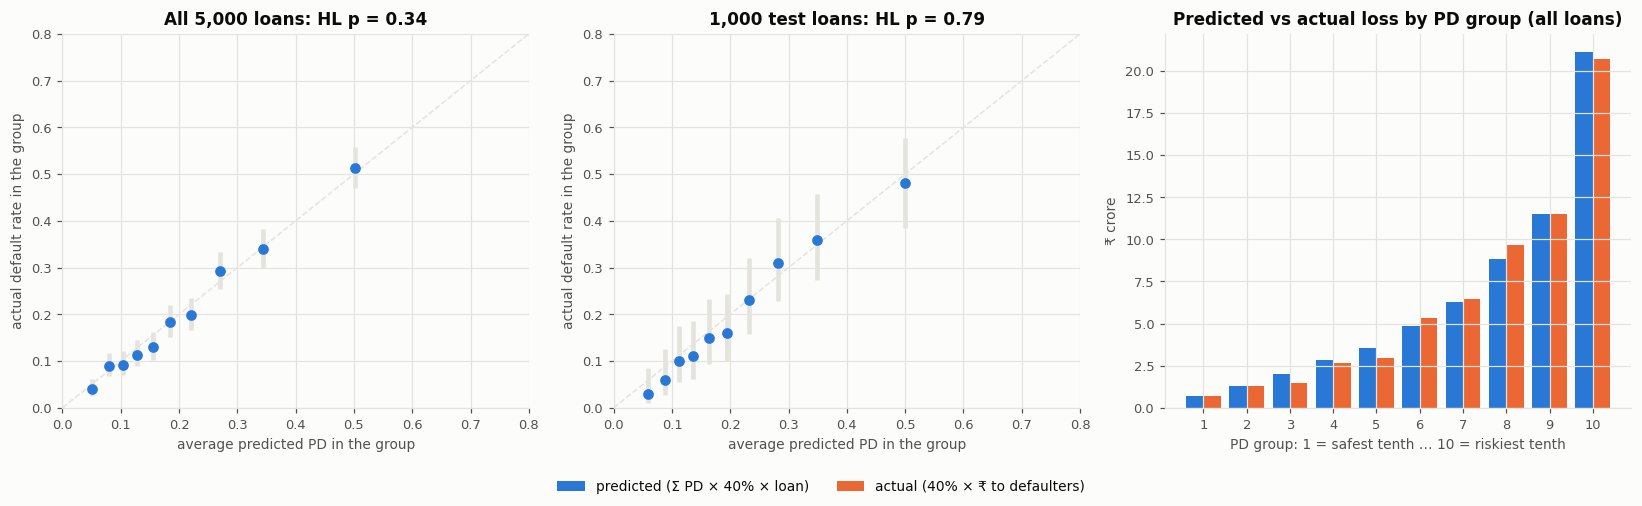

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (name, t) in zip(axes[:2], SETS.items()):
    _, hl_p, g = hosmer_lemeshow(t.Default_Flag.to_numpy(), t.PD_challenger.to_numpy())
    rate = g.O / g.n
    lo, hi = proportion_confint(g.O, g.n, method="wilson")            # 95% range of each group's actual rate
    ax.plot([0, 0.8], [0, 0.8], color=GRID, ls="--", lw=1)
    ax.errorbar(g.avg_pd, rate, yerr=[rate - lo, hi - rate], fmt="o", color=BLUE, ecolor=GRID, elinewidth=3)
    ax.set_xlim(0, 0.8); ax.set_ylim(0, 0.8)
    ax.set_xlabel("average predicted PD in the group"); ax.set_ylabel("actual default rate in the group")
    ax.set_title(f"{name}: HL p = {hl_p:.2f}")

# Right: predicted vs actual loss per PD group (all loans).
t = df.assign(group=pd.qcut(df.PD_challenger.rank(method="first"), 10, labels=False) + 1)
t = t.assign(pred=LGD * t.PD_challenger * t.Loan_Amount / CRORE, act=LGD * t.Default_Flag * t.Loan_Amount / CRORE)
by_group = t.groupby("group")[["pred", "act"]].sum().rename(columns={"pred": "Predicted loss", "act": "Actual loss"})
x = np.arange(1, 11); w = 0.4
axes[2].bar(x - w / 2, by_group["Predicted loss"], w, color=BLUE, label="predicted (Σ PD × 40% × loan)")
axes[2].bar(x + w / 2, by_group["Actual loss"], w, color=ORANGE, label="actual (40% × ₹ to defaulters)")
axes[2].set_xticks(x); axes[2].set_xlabel("PD group: 1 = safest tenth … 10 = riskiest tenth")
axes[2].set_ylabel("₹ crore"); axes[2].set_title("Predicted vs actual loss by PD group (all loans)")
fig.legend(*axes[2].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_chart(fig, "01_calibration")
plt.show()
save_table(by_group.reset_index(), "calibration_rupees_by_group")

## 2b. Platt scaling: only if a calibration check fails (decision M2-14)

**What it is:** a one-input logistic regression applied to the model's own output:

```text
score         = logit(PD) = ln(PD ÷ (1 − PD))
corrected PD  = 1 ÷ (1 + e^−(a + b × score))
a shifts all PDs up or down; b stretches or squeezes them
```

- It is fitted on the **training loans' PDs only** and then applied to every loan, so the test loans stay a clean check.
- It **never changes the ranking** (riskier stays riskier), so ROC-AUC is unchanged. Only the PD *level* moves.

**The rule:** applied only if any of the four checks fails on either set. The code is always here; it only acts when needed.

In [5]:
if CALIBRATED_OK:
    df["Predicted_PD"] = df.PD_challenger
    PLATT = {"applied": False, "reason": "all four calibration checks pass on all 5,000 and on the 1,000 test loans"}
    print("Platt scaling NOT applied:", PLATT["reason"] + ".")
    print("Predicted_PD = the lasso PD from Task 1, unchanged.")
else:
    train = df[~df.Is_Test]
    platt = sm.Logit(train.Default_Flag, sm.add_constant(logit(train.PD_challenger))).fit(disp=0)
    a, b = platt.params
    df["Predicted_PD"] = 1 / (1 + np.exp(-(a + b * logit(df.PD_challenger))))
    PLATT = {"applied": True, "a": float(a), "b": float(b)}
    print(f"Platt scaling applied: corrected PD = 1 ÷ (1 + e^−({a:+.3f} + {b:.3f} × logit(PD)))")
    after = pd.DataFrame({name: calibration_checks(t.assign(Predicted_PD=df.loc[t.index, "Predicted_PD"]), "Predicted_PD")
                          for name, t in SETS.items()})
    display(pd.concat({"Before": calib.loc[PASS_COLS], "After": after.loc[PASS_COLS]}))
    save_table(after.reset_index(names="Measure"), "calibration_checks_after_platt")

Platt scaling NOT applied: all four calibration checks pass on all 5,000 and on the 1,000 test loans.
Predicted_PD = the lasso PD from Task 1, unchanged.


## 3. Apply the brief's risk bands

| Predicted_PD | Risk_Category |
| --- | --- |
| under 5% | Low |
| 5% to under 15% | Medium |
| 15% to under 30% | High |
| 30% and above | Very High |

A PD exactly on a cut-off goes to the higher band (e.g. exactly 15.0% is High). That is the cautious side.

In [6]:
BANDS = ["Low", "Medium", "High", "Very High"]
CUTS = [0.0, 0.05, 0.15, 0.30, 1.0 + 1e-9]          # right=False: each band includes its lower edge
WIDTH = {"Low": 0.05, "Medium": 0.10, "High": 0.15, "Very High": 0.15}   # band width used by test ③ (M2-18)
RANGE_TEXT = {"Low": "under 5%", "Medium": "5–15%", "High": "15–30%", "Very High": "30% and above"}

df["Risk_Category"] = pd.cut(df.Predicted_PD, CUTS, right=False, labels=BANDS)
assert df.Risk_Category.notna().all()
display(df.Risk_Category.value_counts().reindex(BANDS).rename("Loans").to_frame()
          .assign(Share=lambda t: t.Loans / t.Loans.sum()).style.format({"Share": "{:.1%}"}))

,Loans,Share
Risk_Category,,
Low,220,4.4%
Medium,1935,38.7%
High,1824,36.5%
Very High,1021,20.4%


## 4. The four band tests (decisions M2-04, M2-18)

| # | Test | Pass line |
| --- | --- | --- |
| ① | **Inside its range:** do the band's loans default at a rate inside the band's PD range? | Actual default rate lies inside the range |
| ② | **Rising clearly:** does each band default clearly more than the one below? | Chi-square across all bands p < 0.05, **and** each step up (one-sided two-proportion test) p < 0.05 |
| ③ | **Enough loans:** is the band big enough to measure its rate reliably? | 95% range of the actual rate narrower than the band (Low 5, Medium 10, High 15, Very High 15 points) |
| ④ | **Economics:** does interest still beat the expected loss as risk rises? | Margin = average interest − average PD × 40% **falls** band to band and is **negative for Very High** |

**Where they decide:** on **all 5,000 loans**, since every PD there is honest. On the **1,000 test loans**, ① and the rising order are checked; ② and ③ are reported only, because the smallest band holds very few test loans.

**The fallback, if a band fails a deciding test:** it is **merged with its neighbour** and the tests are re-run, with the change recorded. Cut-offs are never moved to make a test pass.

**The formulas:**

```text
Wilson 95% range for a default rate (d defaults out of n loans, r = d ÷ n, z = 1.96):
    centre = (r + z² ÷ 2n) ÷ (1 + z² ÷ n)
    half   = z × √( r(1 − r) ÷ n + z² ÷ 4n² ) ÷ (1 + z² ÷ n)
    range  = centre ± half          (better than r ± 1.96 × √(r(1 − r) ÷ n) when n is small or r near 0)

Chi-square across bands:
    expected defaults in a band if all bands shared the overall rate = loans in band × overall rate
    χ² = Σ (actual − expected)² ÷ expected, over defaults and non-defaults in every band
    degrees of freedom = bands − 1;  small p → the bands' default rates really differ

Step-up test (two-proportion z-test, one-sided):
    z = (r_upper − r_lower) ÷ √( r̄(1 − r̄)(1/n_upper + 1/n_lower) )     r̄ = both bands' defaults ÷ both bands' loans
    p = chance of a step this large if the upper band were really no riskier

Margin (% of the loan, per year) = average interest rate − average PD × 40%
    the brief's test: does the interest earned beat the expected loss?
```

In [7]:
def band_table(t: pd.DataFrame, bands: list, width: dict) -> pd.DataFrame:
    """Per band: loans, defaults, actual rate and its Wilson 95% range, average PD and interest, margin."""
    g = t.groupby("Risk_Category", observed=False)
    out = pd.DataFrame({"Loans": g.size(), "Defaults": g.Default_Flag.sum(), "Average PD": g.Predicted_PD.mean(),
                        "Average interest (%)": g.Interest_Rate.mean()}).reindex(bands)
    out["Actual default rate"] = out.Defaults / out.Loans
    lo, hi = proportion_confint(out.Defaults, out.Loans, method="wilson")
    out["95% low"], out["95% high"] = lo, hi
    out["Range width"] = out["95% high"] - out["95% low"]
    out["Band width"] = [width[b] for b in bands]
    out["Expected loss a year (%)"] = out["Average PD"] * LGD * 100
    out["Margin (%)"] = out["Average interest (%)"] - out["Expected loss a year (%)"]
    return out


def band_tests(t: pd.DataFrame, bands: list, lower: dict, upper: dict, width: dict):
    """Run tests ①–④; return the band table with pass flags, and the step-up / chi-square results."""
    tab = band_table(t, bands, width)
    tab["Range"] = [f"{lower[b]:.0%} and above" if upper[b] > 1 else f"{lower[b]:.0%} to under {upper[b]:.0%}"
                    for b in bands]
    tab["① Inside range"] = [(lower[b] <= r < upper[b]) for b, r in zip(bands, tab["Actual default rate"])]
    tab["③ Enough loans"] = tab["Range width"] < tab["Band width"]
    # ② chi-square across bands (defaults vs non-defaults) and each step up.
    contingency = np.array([tab.Defaults, tab.Loans - tab.Defaults])
    chi2, chi_p, dof, _ = stats.chi2_contingency(contingency)
    steps = []
    for low_b, up_b in zip(bands[:-1], bands[1:]):
        z, p = proportions_ztest([tab.loc[up_b, "Defaults"], tab.loc[low_b, "Defaults"]],
                                 [tab.loc[up_b, "Loans"], tab.loc[low_b, "Loans"]], alternative="larger")
        steps.append({"Step": f"{low_b} → {up_b}", "Lower band rate": tab.loc[low_b, "Actual default rate"],
                      "Upper band rate": tab.loc[up_b, "Actual default rate"], "z": z, "p-value": p, "Pass": p < 0.05})
    steps = pd.DataFrame(steps)
    rising_pass = (chi_p < 0.05) and bool(steps.Pass.all())
    margins = tab["Margin (%)"].to_numpy()
    economics_pass = bool(np.all(np.diff(margins) < 0) and margins[-1] < 0)
    return tab, steps, {"chi2": chi2, "dof": dof, "p": chi_p, "② Rising clearly": rising_pass,
                        "④ Economics": economics_pass}


def bounds(bands: list, cuts: list):
    """Lower and upper PD edge of each band."""
    return dict(zip(bands, cuts[:-1])), dict(zip(bands, cuts[1:]))


# ---- Run the tests on all 5,000 loans; apply the merge fallback if a deciding test fails ---------
bands, cuts, width = list(BANDS), list(CUTS), dict(WIDTH)
MERGES = []
while True:
    lower, upper = bounds(bands, cuts)
    df["Risk_Category"] = pd.cut(df.Predicted_PD, cuts, right=False, labels=bands)
    tab_all, steps_all, overall_all = band_tests(df, bands, lower, upper, width)
    failing = [b for b in bands if not (tab_all.loc[b, "① Inside range"] and tab_all.loc[b, "③ Enough loans"])]
    if not overall_all["② Rising clearly"]:
        failing += [s.split(" → ")[0] for s in steps_all.loc[~steps_all.Pass, "Step"]]
    if not failing or len(bands) <= 2:
        break
    worst = failing[0]                                            # merge the first failing band with a neighbour
    i = bands.index(worst)
    j = i + 1 if i == 0 else i - 1 if i == len(bands) - 1 else (
        i - 1 if abs(tab_all["Actual default rate"].iloc[i - 1] - tab_all["Actual default rate"].iloc[i])
        < abs(tab_all["Actual default rate"].iloc[i + 1] - tab_all["Actual default rate"].iloc[i]) else i + 1)
    keep, drop = sorted([i, j])
    new_name = f"{bands[keep]}+{bands[drop]}"
    MERGES.append(f"{bands[i]} failed; merged with {bands[j]} into '{new_name}'")
    width[new_name] = width[bands[keep]] + width[bands[drop]]
    cuts.pop(drop)
    bands = bands[:keep] + [new_name] + bands[drop + 1:]
FINAL_BANDS, FINAL_CUTS = bands, cuts

print("Merges needed:", MERGES or "none: the brief's four bands are kept")
show_cols = ["Range", "Loans", "Defaults", "Actual default rate", "95% low", "95% high", "Average PD",
             "① Inside range", "Range width", "Band width", "③ Enough loans",
             "Average interest (%)", "Expected loss a year (%)", "Margin (%)"]
fmt = {"Actual default rate": "{:.1%}", "95% low": "{:.1%}", "95% high": "{:.1%}", "Average PD": "{:.1%}",
       "Range width": "{:.1%}", "Band width": "{:.0%}", "Average interest (%)": "{:.2f}",
       "Expected loss a year (%)": "{:.2f}", "Margin (%)": "{:+.2f}"}
print("ALL 5,000 LOANS (deciding)")
display(tab_all[show_cols].style.format(fmt))
display(steps_all.style.format({"Lower band rate": "{:.1%}", "Upper band rate": "{:.1%}", "z": "{:.2f}", "p-value": "{:.2g}"}))
print(f"② Chi-square across bands = {overall_all['chi2']:.1f} ({overall_all['dof']} degrees of freedom), "
      f"p = {overall_all['p']:.2g}  →  rising clearly: {overall_all['② Rising clearly']}")
print(f"④ Economics (margin falls band to band and is negative for the riskiest band): {overall_all['④ Economics']}")

Merges needed: none: the brief's four bands are kept
ALL 5,000 LOANS (deciding)


,Range,Loans,Defaults,Actual default rate,95% low,95% high,Average PD,① Inside range,Range width,Band width,③ Enough loans,Average interest (%),Expected loss a year (%),Margin (%)
Risk_Category,,,,,,,,,,,,,,
Low,0% to under 5%,220,7,3.2%,1.5%,6.4%,4.0%,True,4.9%,5%,True,7.54,1.59,+5.95
Medium,5% to under 15%,1935,180,9.3%,8.1%,10.7%,10.1%,True,2.6%,10%,True,8.11,4.04,+4.07
High,15% to under 30%,1824,374,20.5%,18.7%,22.4%,21.2%,True,3.7%,15%,True,9.59,8.49,+1.10
Very High,30% and above,1021,436,42.7%,39.7%,45.8%,42.1%,True,6.1%,15%,True,12.51,16.82,-4.31


,Step,Lower band rate,Upper band rate,z,p-value,Pass
0,Low → Medium,3.2%,9.3%,3.06,0.0011,True
1,Medium → High,9.3%,20.5%,9.68,1.8e-22,True
2,High → Very High,20.5%,42.7%,12.59,1.3e-36,True


② Chi-square across bands = 507.6 (3 degrees of freedom), p = 1.1e-109  →  rising clearly: True
④ Economics (margin falls band to band and is negative for the riskiest band): True


In [8]:
# ---- Consistency check on the 1,000 test loans (① and rising order decide; ② and ③ reported) ----
lower, upper = bounds(FINAL_BANDS, FINAL_CUTS)
test = df[df.Is_Test]
tab_test, steps_test, overall_test = band_tests(test, FINAL_BANDS, lower, upper, width)
rising_order_test = bool(np.all(np.diff(tab_test["Actual default rate"].to_numpy()) > 0))
print("1,000 TEST LOANS (consistency check)")
display(tab_test[show_cols].style.format(fmt))
display(steps_test.style.format({"Lower band rate": "{:.1%}", "Upper band rate": "{:.1%}", "z": "{:.2f}", "p-value": "{:.2g}"}))
print(f"① Every band's actual rate inside its range: {bool(tab_test['① Inside range'].all())}")
print(f"Rates rise band to band: {rising_order_test}")
print(f"② and ③ (reported only): chi-square p = {overall_test['p']:.2g}; step tests passing: "
      f"{int(steps_test.Pass.sum())} of {len(steps_test)}; bands with enough test loans: "
      f"{int(tab_test['③ Enough loans'].sum())} of {len(FINAL_BANDS)}")

verdict = pd.DataFrame({
    "Test": ["① Inside its range", "② Rising clearly", "③ Enough loans", "④ Economics"],
    "All 5,000 loans (deciding)": [bool(tab_all["① Inside range"].all()), overall_all["② Rising clearly"],
                                   bool(tab_all["③ Enough loans"].all()), overall_all["④ Economics"]],
    "1,000 test loans": [bool(tab_test["① Inside range"].all()),
                         f"order {'rises' if rising_order_test else 'does not rise'}; significance reported only",
                         "reported only", overall_test["④ Economics"]],
})
display(verdict)
BANDS_JUSTIFIED = bool(verdict["All 5,000 loans (deciding)"].all()) and not MERGES
save_table(tab_all.reset_index(names="Risk_Category"), "band_tests_all_loans")
save_table(tab_test.reset_index(names="Risk_Category"), "band_tests_test_loans")
save_table(pd.concat({"All 5,000": steps_all, "Test 1,000": steps_test}).reset_index(level=0, names="Set"), "band_step_tests")
save_table(verdict, "band_tests_verdict")

1,000 TEST LOANS (consistency check)


,Range,Loans,Defaults,Actual default rate,95% low,95% high,Average PD,① Inside range,Range width,Band width,③ Enough loans,Average interest (%),Expected loss a year (%),Margin (%)
Risk_Category,,,,,,,,,,,,,,
Low,0% to under 5%,24,0,0.0%,0.0%,13.8%,4.2%,True,13.8%,5%,False,7.61,1.70,+5.91
Medium,5% to under 15%,376,30,8.0%,5.6%,11.2%,10.2%,True,5.5%,10%,True,8.10,4.09,+4.01
High,15% to under 30%,383,82,21.4%,17.6%,25.8%,21.4%,True,8.2%,15%,True,9.48,8.56,+0.92
Very High,30% and above,217,87,40.1%,33.8%,46.7%,41.5%,True,12.9%,15%,True,12.54,16.61,-4.07


,Step,Lower band rate,Upper band rate,z,p-value,Pass
0,Low → Medium,0.0%,8.0%,1.44,0.075,False
1,Medium → High,8.0%,21.4%,5.22,9.1e-08,True
2,High → Very High,21.4%,40.1%,4.89,5.1e-07,True


① Every band's actual rate inside its range: True
Rates rise band to band: True
② and ③ (reported only): chi-square p = 1.4e-20; step tests passing: 2 of 3; bands with enough test loans: 3 of 4


,Test,"All 5,000 loans (deciding)","1,000 test loans"
0,① Inside its range,True,True
1,② Rising clearly,True,order rises; significance reported only
2,③ Enough loans,True,reported only
3,④ Economics,True,True


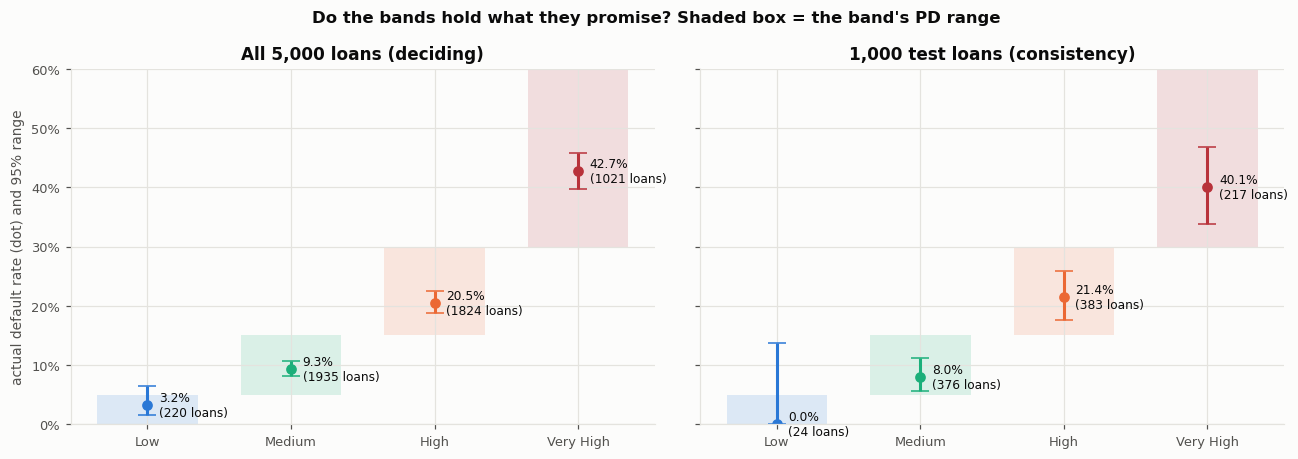

In [9]:
# Chart: each band's actual default rate with its 95% range, drawn against the band's PD range.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (name, tab) in zip(axes, [("All 5,000 loans (deciding)", tab_all), ("1,000 test loans (consistency)", tab_test)]):
    for k, b in enumerate(FINAL_BANDS):
        top = min(upper[b], 0.6)
        ax.add_patch(plt.Rectangle((k - 0.35, lower[b]), 0.7, top - lower[b],
                                   color=RISK_COLOURS.get(b, GRID), alpha=0.15, lw=0))
        r, lo_, hi_ = tab.loc[b, ["Actual default rate", "95% low", "95% high"]]
        ax.errorbar(k, r, yerr=[[r - lo_], [hi_ - r]], fmt="o", color=RISK_COLOURS.get(b, INK), capsize=6, lw=2)
        ax.text(k + 0.08, r, f"{r:.1%}\n({int(tab.loc[b, 'Loans'])} loans)", fontsize=8, va="center")
    ax.set_xticks(range(len(FINAL_BANDS)), FINAL_BANDS)
    ax.set_ylim(0, 0.6); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(name)
axes[0].set_ylabel("actual default rate (dot) and 95% range")
fig.suptitle("Do the bands hold what they promise? Shaded box = the band's PD range", fontweight="bold")
fig.tight_layout()
save_chart(fig, "02_band_tests")
plt.show()

## 5. The bands in rupees (Board view)

For each band:

```text
₹ lent                     = Σ Loan_Amount
Interest a year            = Σ Interest_Rate × Loan_Amount
Expected loss a year       = Σ Predicted_PD × 40% × Loan_Amount        (the brief's ECL, one-year view)
Actual loss                = 40% × ₹ lent to borrowers who defaulted
Interest minus expected loss = what the band earns after expected defaults, before the cost of funding and running the loans
```

,Loans,₹ lent (crore),Interest a year (crore),Expected loss a year (crore),Actual loss at 40% (crore),Share of loans,Share of ₹ lent,Share of expected loss,Interest minus expected loss (crore)
Risk_Category,,,,,,,,,
Low,220,13.3,1.0,0.2,0.1,4.4%,2.1%,0.3%,0.8
Medium,"1,935",180.5,14.8,7.6,6.8,38.7%,28.2%,12.0%,7.3
High,"1,824",256.1,25.2,22.2,23.0,36.5%,40.0%,35.3%,3.0
Very High,"1,021",189.8,24.8,33.0,32.7,20.4%,29.7%,52.4%,-8.3
Whole book,"5,000",639.7,65.8,63.0,62.7,100.0%,100.0%,100.0%,2.8


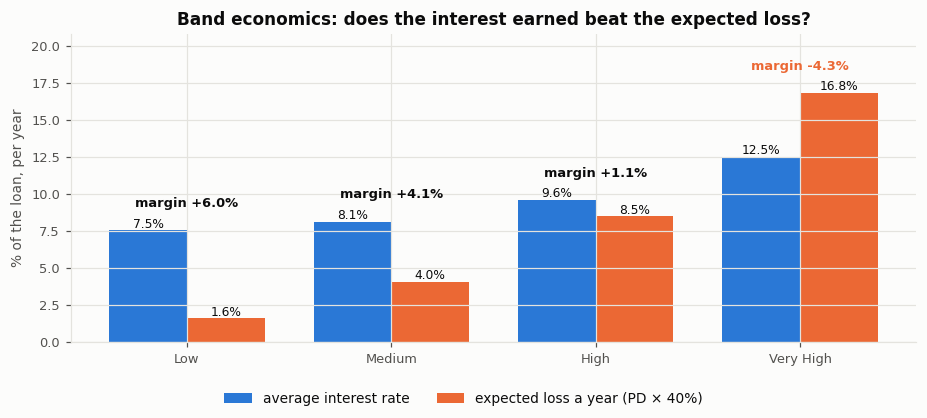

In [10]:
def rupee_profile(t: pd.DataFrame, bands: list) -> pd.DataFrame:
    """₹ view per band: lending, interest, expected and actual loss."""
    g = t.assign(Interest=t.Interest_Rate / 100 * t.Loan_Amount, EL=t.Predicted_PD * LGD * t.Loan_Amount,
                 AL=LGD * t.Default_Flag * t.Loan_Amount).groupby("Risk_Category", observed=False)
    out = pd.DataFrame({"Loans": g.size(), "₹ lent (crore)": g.Loan_Amount.sum() / CRORE,
                        "Interest a year (crore)": g.Interest.sum() / CRORE,
                        "Expected loss a year (crore)": g.EL.sum() / CRORE,
                        "Actual loss at 40% (crore)": g.AL.sum() / CRORE}).reindex(bands)
    out["Share of loans"] = out.Loans / out.Loans.sum()
    out["Share of ₹ lent"] = out["₹ lent (crore)"] / out["₹ lent (crore)"].sum()
    out["Share of expected loss"] = out["Expected loss a year (crore)"] / out["Expected loss a year (crore)"].sum()
    out["Interest minus expected loss (crore)"] = out["Interest a year (crore)"] - out["Expected loss a year (crore)"]
    total = out.sum(numeric_only=True)
    out.loc["Whole book"] = total
    return out


profile = rupee_profile(df, FINAL_BANDS)
display(profile.style.format("{:,.1f}").format("{:.1%}", subset=["Share of loans", "Share of ₹ lent", "Share of expected loss"])
               .format("{:,.0f}", subset=["Loans"]))
save_table(profile.reset_index(names="Risk_Category"), "band_rupee_profile")

# Retail vs Corporate within each band.
seg = (df.groupby(["Risk_Category", "Customer_Type"], observed=False)
         .agg(Loans=("Loan_ID", "size"), Default_rate=("Default_Flag", "mean"),
              Lent_crore=("Loan_Amount", lambda a: a.sum() / CRORE))
         .unstack("Customer_Type"))
display(seg.style.format("{:.1%}", subset=[c for c in seg.columns if c[0] == "Default_rate"])
           .format("{:,.1f}", subset=[c for c in seg.columns if c[0] == "Lent_crore"]))
save_table(seg.set_axis([f"{a} ({c})" for a, c in seg.columns], axis=1).reset_index(), "band_by_customer_type")

# Chart: average interest vs expected loss a year, per band (both as % of the loan).
fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(FINAL_BANDS)); w = 0.38
b1 = ax.bar(x - w / 2, tab_all["Average interest (%)"], w, color=BLUE, label="average interest rate")
b2 = ax.bar(x + w / 2, tab_all["Expected loss a year (%)"], w, color=ORANGE, label="expected loss a year (PD × 40%)")
ax.bar_label(b1, fmt="%.1f%%", fontsize=8); ax.bar_label(b2, fmt="%.1f%%", fontsize=8)
for k, m in enumerate(tab_all["Margin (%)"]):
    ax.text(k, max(tab_all["Average interest (%)"].iloc[k], tab_all["Expected loss a year (%)"].iloc[k]) + 1.6,
            f"margin {m:+.1f}%", ha="center", fontsize=8.5, color=INK if m >= 0 else ORANGE, fontweight="bold")
ax.set_xticks(x, FINAL_BANDS); ax.set_ylabel("% of the loan, per year")
ax.set_ylim(0, max(tab_all["Expected loss a year (%)"].max(), tab_all["Average interest (%)"].max()) + 4)
ax.set_title("Band economics: does the interest earned beat the expected loss?")
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_chart(fig, "03_band_economics")
plt.show()

## 6. The scorecard's bands against the bank's own view

The **champion's PD** (the bank's interest rate, turned into a probability in Task 1) is placed in the **same bands**. The cross-table then shows, for every pair (bank's band, scorecard's band):
- how many loans and ₹ fall there;
- the **actual default rate** in that cell, which shows who was right when the two disagree.

Cells on the diagonal are loans where both agree. Off-diagonal cells are where the scorecard sees the borrower as safer or riskier than the bank's price suggests: the **mispricing** found in Task 1, now band by band.

Same band under both views: 66.4% of loans
The bank's price never signals Low risk: its lowest PD is 6.1% (at the 6.0% floor rate), so no loan falls below 5%. The scorecard places 220 loans there.
Loans (rows = bank's view from its price, columns = scorecard):


Risk_Category,Low,Medium,High,Very High
Champion_Category,,,,
Low,0,0,0,0
Medium,198,1505,554,11
High,22,428,1128,322
Very High,0,2,142,688


Actual default rate in each cell:


Risk_Category,Low,Medium,High,Very High
Champion_Category,,,,
Low,—,—,—,—
Medium,3.0%,9.5%,15.5%,45.5%
High,4.5%,8.6%,21.5%,34.5%
Very High,—,0.0%,32.4%,46.5%


₹ lent in each cell (crore):


Risk_Category,Low,Medium,High,Very High
Champion_Category,,,,
Low,0.0,0.0,0.0,0.0
Medium,11.5,136.0,64.6,1.4
High,1.7,44.1,159.3,45.7
Very High,0.0,0.3,32.2,142.6


,Group,Loans,₹ lent (crore),Actual default rate,Average rate charged (%)
0,Scorecard puts in a SAFER band than the bank's price,792,89.9,11.4%,9.45
1,Same band,3321,438.0,21.2%,9.67
2,Scorecard puts in a RISKIER band than the bank's price,887,111.8,22.8%,9.05


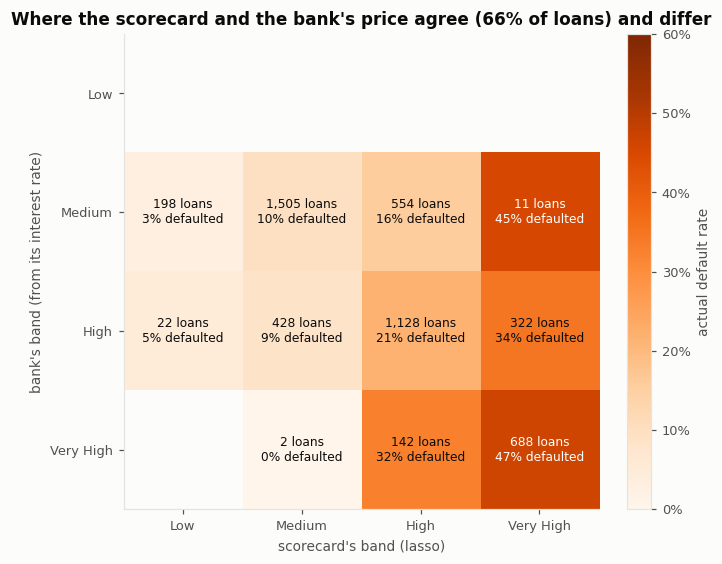

In [11]:
df["Champion_Category"] = pd.cut(df.PD_champion, FINAL_CUTS, right=False, labels=FINAL_BANDS)
cross_n = pd.crosstab(df.Champion_Category, df.Risk_Category).reindex(index=FINAL_BANDS, columns=FINAL_BANDS, fill_value=0)
cross_rate = (df.pivot_table(index="Champion_Category", columns="Risk_Category", values="Default_Flag",
                             aggfunc="mean", observed=False).reindex(index=FINAL_BANDS, columns=FINAL_BANDS))
cross_amt = (df.pivot_table(index="Champion_Category", columns="Risk_Category", values="Loan_Amount",
                            aggfunc="sum", observed=False).reindex(index=FINAL_BANDS, columns=FINAL_BANDS) / CRORE)
agree = np.trace(cross_n.to_numpy()) / cross_n.to_numpy().sum()
print(f"Same band under both views: {agree:.1%} of loans")
print(f"The bank's price never signals Low risk: its lowest PD is {df.PD_champion.min():.1%} (at the 6.0% floor rate), "
      f"so no loan falls below 5%. The scorecard places {int((df.Risk_Category == FINAL_BANDS[0]).sum())} loans there.")
print("Loans (rows = bank's view from its price, columns = scorecard):"); display(cross_n)
print("Actual default rate in each cell:"); display(cross_rate.style.format("{:.1%}", na_rep="—"))
print("₹ lent in each cell (crore):"); display(cross_amt.style.format("{:,.1f}", na_rep="—"))

# Summary of disagreement: scorecard safer than the bank's price, or riskier.
order = {b: k for k, b in enumerate(FINAL_BANDS)}
diff = df.Risk_Category.map(order).astype(int) - df.Champion_Category.map(order).astype(int)
disagree = pd.DataFrame([{"Group": g, "Loans": int(m.sum()), "₹ lent (crore)": df.Loan_Amount[m].sum() / CRORE,
                          "Actual default rate": df.Default_Flag[m].mean(),
                          "Average rate charged (%)": df.Interest_Rate[m].mean()}
                         for g, m in [("Scorecard puts in a SAFER band than the bank's price", diff < 0),
                                      ("Same band", diff == 0),
                                      ("Scorecard puts in a RISKIER band than the bank's price", diff > 0)]])
display(disagree.style.format({"₹ lent (crore)": "{:,.1f}", "Actual default rate": "{:.1%}",
                               "Average rate charged (%)": "{:.2f}"}))
save_table(cross_n.reset_index(), "cross_bands_loans")
save_table(cross_rate.reset_index(), "cross_bands_default_rate")
save_table(cross_amt.reset_index(), "cross_bands_rupees")
save_table(disagree, "cross_bands_disagreement")

fig, ax = plt.subplots(figsize=(7.2, 5.2))
im = ax.imshow(cross_rate.to_numpy(dtype=float), cmap="Oranges", vmin=0, vmax=0.6)
for i in range(len(FINAL_BANDS)):
    for j in range(len(FINAL_BANDS)):
        n = cross_n.iat[i, j]
        if n:
            ax.text(j, i, f"{n:,} loans\n{cross_rate.iat[i, j]:.0%} defaulted", ha="center", va="center", fontsize=8,
                    color="white" if cross_rate.iat[i, j] > 0.35 else INK)
ax.set_xticks(range(len(FINAL_BANDS)), FINAL_BANDS); ax.set_yticks(range(len(FINAL_BANDS)), FINAL_BANDS)
ax.set_xlabel("scorecard's band (lasso)"); ax.set_ylabel("bank's band (from its interest rate)")
ax.grid(False)
ax.set_title(f"Where the scorecard and the bank's price agree ({agree:.0%} of loans) and differ")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, format=plt.FuncFormatter(lambda v, _: f"{v:.0%}"),
             label="actual default rate")
fig.tight_layout()
save_chart(fig, "04_scorecard_vs_bank_bands")
plt.show()

## 7. What the results say

### The ML case: the PDs can be trusted as probabilities (step 2)

| Check (pass line) | All 5,000 loans | 1,000 test loans |
| --- | --- | --- |
| Average PD vs actual default rate | 20.4% vs 19.9% | 21.2% vs 19.9% |
| 1. Intercept (95% range includes 0) | −0.03 (−0.11 to +0.04) ✓ | −0.09 (−0.25 to +0.08) ✓ |
| 2. Slope (95% range includes 1) | 1.04 (0.95 to 1.14) ✓ | 1.13 (0.90 to 1.35) ✓ |
| 3. Hosmer–Lemeshow (p > 0.05) | p = 0.34 ✓ | p = 0.79 ✓ |
| 4. Predicted vs actual loss (range of difference includes 0) | ₹63.0 vs ₹62.7 crore (−₹3.8 to +₹4.2 crore) ✓ | ₹12.9 vs ₹12.7 crore (−₹1.6 to +₹1.9 crore) ✓ |

- **All four checks pass on both sets, so Platt scaling is not needed.** Predicted_PD is the lasso PD from Task 1, unchanged.
- Every one of the 10 PD groups sits close to the diagonal, from about 5% in the safest tenth to about 50% in the riskiest.
- On the test loans, PDs run about 1.3 points high on average, which is within chance.
- **In rupees**, the PDs predict a loss of ₹63.0 crore against ₹62.7 crore that actually happened, group by group as well as in total. So Task 3 can use these PDs directly for ECL.

### The brief's bands are justified (step 4)

| Band | Loans | Actual default (95% range) | ① Inside | ③ Range vs band | Average interest | Expected loss a year (PD × 40%) | ④ Margin |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Low (< 5%) | 220 (4.4%) | 3.2% (1.6–6.4%) | ✓ | 4.9 vs 5 points ✓ | 7.5% | 1.6% | +6.0% |
| Medium (5–15%) | 1,935 (38.7%) | 9.3% (8.1–10.7%) | ✓ | 2.6 vs 10 ✓ | 8.1% | 4.0% | +4.1% |
| High (15–30%) | 1,824 (36.5%) | 20.5% (18.7–22.4%) | ✓ | 3.7 vs 15 ✓ | 9.6% | 8.5% | +1.1% |
| Very High (≥ 30%) | 1,021 (20.4%) | 42.7% (39.7–45.8%) | ✓ | 6.1 vs 15 ✓ | 12.5% | 16.8% | −4.3% |

- **All four tests pass on all 5,000 loans, with no merges.**
  - ① Every band's loans default inside the band's range.
  - ② Default rates rise clearly: chi-square p ≈ 10⁻¹⁰⁹, and every step up is significant (Low → Medium p = 0.001).
  - ③ Every band is big enough.
  - ④ The margin falls band by band and turns negative for Very High.
- **On the 1,000 test loans,** every band's rate is again inside its range, and the rates rise in order (0.0% → 8.0% → 21.4% → 40.1%).
  - As expected, the Low band holds only 24 test loans (0 defaults). So its step to Medium isn't significant there (p = 0.075), and its range is too wide to measure. That is a sample-size limit, reported and not deciding.
- **Caveat:** Low passes test ③ only narrowly on all 5,000 loans (a 4.9-point range against a 5-point band). Genuinely low-risk borrowers are rare in this book. Its rate (3.2%) is still clearly below Medium (9.3%), and its economics are distinct.

**So the cut-offs are not just copied. They are backed by evidence:**
- **ML:** each band holds what it promises, and the bands separate risk clearly.
- **Finance:** each cut-off marks a real change in profitability. Low and Medium earn well above their expected loss. High barely covers it (+1.1% before any cost of funding or running the loan). Very High loses money on average.

### The finance case: the bands in rupees (step 5)

| Band | ₹ lent | Interest a year | Expected loss a year | Interest minus expected loss | Share of ₹ lent | Share of expected loss |
| --- | --- | --- | --- | --- | --- | --- |
| Low | ₹13.3 crore | ₹1.01 crore | ₹0.21 crore | +₹0.80 crore | 2.1% | 0.3% |
| Medium | ₹180.5 crore | ₹14.81 crore | ₹7.56 crore | +₹7.25 crore | 28.2% | 12.0% |
| High | ₹256.1 crore | ₹25.20 crore | ₹22.23 crore | +₹2.97 crore | 40.0% | 35.3% |
| Very High | ₹189.8 crore | ₹24.78 crore | ₹33.03 crore | **−₹8.25 crore** | 29.7% | **52.4%** |
| **Whole book** | **₹639.7 crore** | **₹65.80 crore** | **₹63.04 crore** | **+₹2.76 crore** | 100% | 100% |

- **The whole book earns only ₹2.76 crore a year more in interest than it is expected to lose**, before paying for funds and operations.
- **Very High loans are 20% of loans and 30% of the ₹, but carry 52% of the expected loss, and lose ₹8.25 crore a year on their own.** This is the clearest lever for "fewer defaults".
- **Medium loans earn the most after expected loss** (+₹7.25 crore). This is the business to grow for "lend more".
- Retail and Corporate behave alike in every band (e.g. Very High: 44.2% vs 42.2% default), so one set of bands serves both.

### The scorecard against the bank's own view (step 6)

- **The bank's price never signals Low risk.** Its lowest PD is 6.1%, at the 6.0% floor rate, so no loan falls below 5% on the bank's view. The scorecard finds **220 Low-risk loans that default only 3.2%**. The bank charges them about 7.5%.
- **The two views agree on 66% of loans.** Where they disagree, the scorecard is usually right:

| Bank's band (from its price) | Scorecard's band | Loans | ₹ lent | Actual default |
| --- | --- | --- | --- | --- |
| Medium | **Low** | 198 | ₹11.5 crore | **3.0%** |
| High | **Medium** | 428 | ₹44.1 crore | **8.6%** |
| Medium | **High** | 554 | ₹64.6 crore | **15.5%** |
| High | **Very High** | 322 | ₹45.7 crore | **34.5%** |

- In each row above, the actual default rate lands in the **scorecard's** band, not the bank's.
- **One exception, where the bank is right:** 142 loans priced as Very High that the scorecard calls High actually defaulted 32.4%, inside Very High.

- **Overall:** loans the scorecard puts in a **safer** band (792 loans, ₹89.9 crore) default **11.4%** but are charged **9.45%** on average. Loans it puts in a **riskier** band (887 loans, ₹111.8 crore) default **22.8%** but are charged only **9.05%**. **The bank charges the safer group more than the riskier group**: that is mispricing, now in rupees and bands.

### What goes to Task 3
- `outputs/task2/loan_pd.csv`: **the brief's deliverable**, Loan_ID · Predicted_PD · Risk_Category for all 5,000 loans.
- `outputs/task2/FINAL_M2_T2_risk_categories.csv`: the same, plus Set and the champion's PD and band. Task 3 needs them for the 73% turning point from Task 1.
- **For Task 3 to decide:**
  - the PDs are calibrated, so ECL = Predicted_PD × 40% × Loan_Amount can be computed directly;
  - Very High loans lose money on average;
  - High loans barely pay before costs;
  - the approval level and the cost assumption decide how much of High is worth keeping.

## 8. Save the outputs

- **`loan_pd.csv`: the brief's deliverable.** Loan_ID, Predicted_PD, Risk_Category for all 5,000 loans.
- **`FINAL_M2_T2_risk_categories.csv`: for Task 3.** The same three columns, plus Set (training / test) and PD_champion (needed for the 73% turning point found in Task 1).
- The tables and charts above, and `key_numbers.json` with the headline numbers of this run.

In [12]:
loan_pd = df[["Loan_ID", "Predicted_PD", "Risk_Category"]].sort_values("Loan_ID").reset_index(drop=True)
assert len(loan_pd) == 5000 and loan_pd.notna().all().all()
save_table(loan_pd.assign(Predicted_PD=loan_pd.Predicted_PD.round(6)), "loan_pd")

handoff = df[["Loan_ID", "Set", "Predicted_PD", "Risk_Category", "PD_champion", "Champion_Category"]].sort_values("Loan_ID")
save_table(handoff.round(6), "FINAL_M2_T2_risk_categories")

key = {
    "loans": len(df), "platt": PLATT, "calibration": {name: {k: (bool(v) if isinstance(v, (bool, np.bool_)) else round(float(v), 4))
                                                          for k, v in calib[name].items()} for name in calib.columns},
    "merges": MERGES, "bands": FINAL_BANDS, "bands_justified": BANDS_JUSTIFIED,
    "band_loans": {b: int(tab_all.loc[b, "Loans"]) for b in FINAL_BANDS},
    "band_actual_rate": {b: round(float(tab_all.loc[b, "Actual default rate"]), 4) for b in FINAL_BANDS},
    "band_margin_pct": {b: round(float(tab_all.loc[b, "Margin (%)"]), 2) for b in FINAL_BANDS},
    "chi2_p_all": float(overall_all["p"]),
    "expected_loss_crore": round(float(profile.loc["Whole book", "Expected loss a year (crore)"]), 2),
    "actual_loss_crore": round(float(profile.loc["Whole book", "Actual loss at 40% (crore)"]), 2),
    "same_band_share": round(float(agree), 4),
}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1), encoding="utf-8")
print(loan_pd.head())
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

   Loan_ID  Predicted_PD Risk_Category
0   200001      0.188580          High
1   200002      0.076655        Medium
2   200003      0.085960        Medium
3   200004      0.476837     Very High
4   200005      0.187931          High
Saved to module_02_credit_risk/outputs/task2
['01_calibration.png', '02_band_tests.png', '03_band_economics.png', '04_scorecard_vs_bank_bands.png', 'band_by_customer_type.csv', 'band_rupee_profile.csv', 'band_step_tests.csv', 'band_tests_all_loans.csv', 'band_tests_test_loans.csv', 'band_tests_verdict.csv', 'calibration_checks.csv', 'calibration_rupees_by_group.csv', 'cross_bands_default_rate.csv', 'cross_bands_disagreement.csv', 'cross_bands_loans.csv', 'cross_bands_rupees.csv', 'key_numbers.json', 'loan_pd.csv', 'task2_handoff.csv']
